# SAA, SNR, and SNRFrob: robust accuracy

The notebook keeps the original SAA/SNR lambda sweep and adds every SNRFrob gamma candidate.
All plotted curves use **test** accuracy and the absolute feature-space radius $\Delta=\|\delta\|_2$.
The old SNR sweep trained on 50,000 examples. The new SNRFrob sweep trained on 40,000 examples.
They appear in separate panels with their own SAA baselines. This makes the training-set difference explicit.

Run all cells with the `deeplearning` kernel. Missing SNRFrob test curves are computed from saved
heads and the existing feature cache. No head is trained again. New evaluation files are saved
under `results/derived`; original experiment files and the validation selection are preserved.
The derived test sweep is descriptive and is not used to select gamma.

The current data use one seed. The figures therefore have no uncertainty bands.
The older runs do not identify their cross-entropy version. Their stored curves are kept as historical results.

In [1]:
from datetime import datetime
from pathlib import Path
import json
import os
import shutil
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

standard_color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

# MiKTeX can be installed on Windows without being on the kernel's PATH.
if shutil.which('latex') is None and os.name == 'nt':
    tex_bin = Path(os.environ.get('LOCALAPPDATA', '')) / 'Programs/MiKTeX/miktex/bin/x64'
    if (tex_bin / 'latex.exe').is_file():
        os.environ['PATH'] = str(tex_bin) + os.pathsep + os.environ['PATH']

use_tex = shutil.which('latex') is not None and shutil.which('dvipng') is not None
if not use_tex:
    warnings.warn('LaTeX or dvipng is absent. Use Computer Modern mathtext for this plot.')

plt.rc('font', family='serif')
plt.rc('text', usetex=use_tex)
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath, amssymb, bm, mathrsfs}'
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 10,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'mathtext.fontset': 'cm',
    'axes.linewidth': 0.65,
    'savefig.facecolor': 'white',
})

colors = [
    '#003f5c', '#2f4b7c', '#665191', '#a05195',
    '#d45087', '#f95d6a', '#ff7c43', '#ffa600',
]
print('Text rendering:', 'LaTeX' if use_tex else 'Computer Modern mathtext')

Text rendering: LaTeX


In [2]:
project_dir = Path.cwd()
if not (project_dir / 'results').is_dir() and (project_dir.parent / 'results').is_dir():
    project_dir = project_dir.parent
results_dir = project_dir / 'results' / 'cifar10_resnet18'
csv_paths = sorted(results_dir.glob('*/results.csv'))
if not csv_paths:
    raise FileNotFoundError(f'No experiment CSV files found in {results_dir}')

frames = []
feature_specs = set()
for csv_path in csv_paths:
    metadata = json.loads(csv_path.with_name('experiment.json').read_text())
    if metadata['arguments'].get('snrfrob_gamma_grid'):
        continue
    frame = pd.read_csv(csv_path)
    frame = frame.loc[frame['method'].isin(['SAA', 'SNR'])].copy()
    if frame.empty:
        continue
    feature_specs.add(json.dumps(metadata['feature_metadata'], sort_keys=True))
    frame['source_run'] = csv_path.parent.name
    frames.append(frame)
if not frames:
    raise ValueError('No SAA or SNR results found.')
if len(feature_specs) != 1:
    raise ValueError('The runs use different feature spaces.')

raw = pd.concat(frames, ignore_index=True)
required = ['method', 'configuration', 'seed', 'snr_lambda', 'mean_test_norm',
            'relative_level', 'absolute_radius', 'clean_accuracy', 'pgd_accuracy',
            'pgd_steps', 'pgd_step_size', 'hyperparameters', 'metric']
missing = set(required) - set(raw.columns)
if missing:
    raise ValueError(f'Missing CSV columns: {sorted(missing)}')

# A repeated run of the same seed is not an independent repeat.
results = raw.drop(columns='source_run').drop_duplicates().copy()
keys = ['method', 'configuration', 'seed', 'relative_level']
if results.duplicated(keys).any():
    raise ValueError('Conflicting results found for the same method, configuration, seed, and level.')

settings = []
for encoded in results['hyperparameters']:
    setting = json.loads(encoded)
    setting.pop('snr_lambda', None)
    settings.append(json.dumps(setting, sort_keys=True))
if len(set(settings)) != 1:
    raise ValueError('Training settings differ beyond the SNR coefficient. Select compatible runs.')
if results['pgd_steps'].nunique() != 1 or results['mean_test_norm'].nunique() != 1:
    raise ValueError('The runs use different attack settings or reference norms.')
if set(results['metric']) != {'feature-space PGD accuracy'}:
    raise ValueError('The CSV files contain a different accuracy metric.')
if set(results['method']) != {'SAA', 'SNR'}:
    raise ValueError('Both SAA and SNR results are required.')
if results.loc[results['method'].eq('SNR'), 'snr_lambda'].isna().any():
    raise ValueError('An SNR coefficient is missing.')

numeric = results[['mean_test_norm', 'relative_level', 'absolute_radius',
                   'clean_accuracy', 'pgd_accuracy', 'pgd_steps', 'pgd_step_size']]
if not np.isfinite(numeric.to_numpy()).all():
    raise ValueError('Nonfinite values found in the results.')
np.testing.assert_allclose(results['absolute_radius'],
                           results['relative_level'] * results['mean_test_norm'], rtol=1e-12)
np.testing.assert_allclose(results['pgd_step_size'], results['absolute_radius'] / 8, rtol=1e-12)
if not results['pgd_accuracy'].between(0, 100).all():
    raise ValueError('PGD accuracy must be in [0, 100].')
if (results['pgd_accuracy'] > results['clean_accuracy'] + 1e-10).any():
    raise ValueError('PGD accuracy exceeds clean accuracy.')

expected_levels = np.arange(11) * 0.008
for key, curve in results.groupby(['method', 'snr_lambda', 'seed'], dropna=False):
    curve = curve.sort_values('relative_level')
    np.testing.assert_allclose(curve['relative_level'], expected_levels, rtol=0, atol=1e-12,
                               err_msg=f'Missing or repeated attack levels for {key}')
    np.testing.assert_allclose(curve.iloc[0]['pgd_accuracy'], curve.iloc[0]['clean_accuracy'])

seed_sets = [tuple(sorted(group['seed'].unique())) for _, group in
             results.groupby(['method', 'snr_lambda'], dropna=False)]
if len(set(seed_sets)) != 1:
    raise ValueError('The curves do not use the same seeds.')

mean_test_norm = results['mean_test_norm'].iloc[0]
pgd_steps = int(results['pgd_steps'].iloc[0])
lambdas = sorted(results.loc[results['method'].eq('SNR'), 'snr_lambda'].unique())
print(f'Loaded {len(frames)} runs; removed {len(raw) - len(results)} identical duplicate rows.')
print(f'SNR coefficients: {lambdas}')
print(f'Seeds: {seed_sets[0]}; PGD steps: {pgd_steps}; mean test norm: {mean_test_norm:.8f}')
print(f'Absolute radius range: 0 to {results["absolute_radius"].max():.6f}')

Loaded 13 runs; removed 132 identical duplicate rows.
SNR coefficients: [np.float64(0.01), np.float64(0.05), np.float64(0.09), np.float64(0.1), np.float64(0.3), np.float64(0.5), np.float64(0.7), np.float64(0.9), np.float64(1.0), np.float64(1.3), np.float64(1.5), np.float64(1.7), np.float64(2.0)]
Seeds: (np.int64(2022),); PGD steps: 10; mean test norm: 27.73392487
Absolute radius range: 0 to 2.218714


In [3]:
summary = (
    results.groupby(['method', 'snr_lambda', 'absolute_radius'], dropna=False)['pgd_accuracy']
    .agg(mean='mean', std='std', seeds='count')
    .reset_index()
)
endpoints = results.loc[results['relative_level'].isin([0.0, 0.08])]
endpoint_table = endpoints.pivot_table(
    index=['method', 'snr_lambda'], columns='relative_level', values='pgd_accuracy',
    aggfunc='mean', dropna=False,
).dropna(how='all').rename(columns={0.0: 'Clean accuracy (%)', 0.08: 'Accuracy at maximum Delta (%)'})
endpoint_table.round(2)

relative_level     Clean accuracy (%)  Accuracy at maximum Delta (%)
method snr_lambda                                                   
SAA    NaN                      87.08                          15.83
SNR    0.01                     86.97                          22.74
       0.05                     86.25                          33.36
       0.09                     85.86                          37.12
       0.10                     85.79                          37.81
       0.30                     84.61                          43.53
       0.50                     84.09                          45.70
       0.70                     83.64                          46.97
       0.90                     83.30                          47.85
       1.00                     83.16                          48.11
       1.30                     82.54                          48.86
       1.50                     82.46                          49.20
       1.70                     82.39                          49.55
       2.00                     81.95                          49.80

Figures and plotted data saved to: results\figures\saa_snr_lambda_sweep_20261109_180716_352501


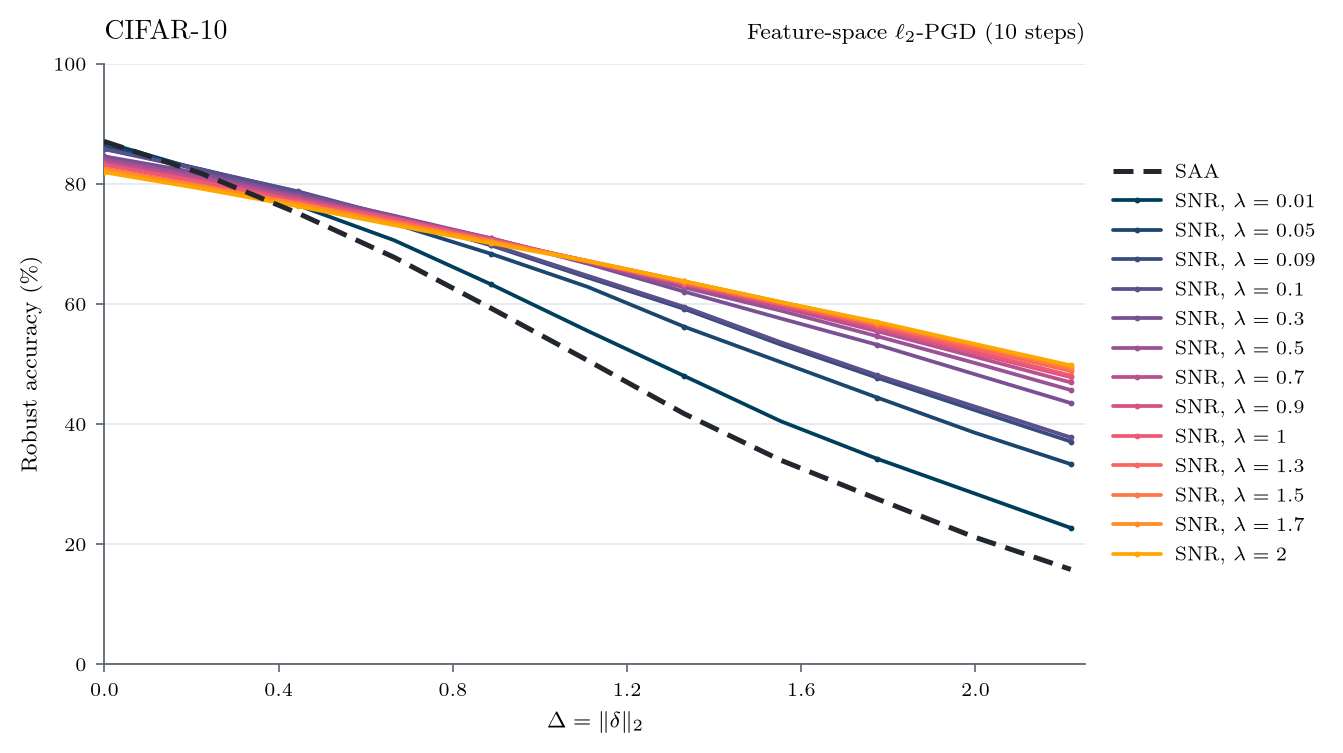

In [4]:
# Extend the supplied palette so that every SNR coefficient has its own color.
snr_palette = LinearSegmentedColormap.from_list('snr_lambda', colors)
snr_colors = snr_palette(np.linspace(0, 1, len(lambdas)))

fig, ax = plt.subplots(figsize=(6.6, 3.65), constrained_layout=True)
fig.set_facecolor('white')
ax.set_facecolor('white')
ax.set_axisbelow(True)
ax.grid(axis='y', color='#dce1e6', linewidth=0.55, alpha=0.85)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#5c6570')
ax.tick_params(direction='out', length=3, width=0.6, color='#5c6570')

saa = summary.loc[summary['method'].eq('SAA')].sort_values('absolute_radius')
ax.plot(saa['absolute_radius'], saa['mean'], label='SAA', color='#22272e',
        linewidth=1.8, linestyle=(0, (4, 2)), zorder=4)
if (saa['seeds'] > 1).all():
    ax.fill_between(saa['absolute_radius'], saa['mean'] - saa['std'],
                    saa['mean'] + saa['std'], color='#22272e', alpha=0.08, linewidth=0)

for coefficient, color in zip(lambdas, snr_colors):
    curve = summary.loc[summary['method'].eq('SNR') & summary['snr_lambda'].eq(coefficient)]
    curve = curve.sort_values('absolute_radius')
    label = rf'SNR, $\lambda={coefficient:g}$'
    ax.plot(curve['absolute_radius'], curve['mean'], color=color, label=label,
            linewidth=1.35, marker='o', markersize=2.1, markevery=2,
            markeredgewidth=0, solid_capstyle='round', zorder=3)
    if (curve['seeds'] > 1).all():
        ax.fill_between(curve['absolute_radius'], curve['mean'] - curve['std'],
                        curve['mean'] + curve['std'], color=color, alpha=0.1, linewidth=0)

ax.set_xlabel(r'$\Delta = \|\delta\|_2$')
ax.set_ylabel(r'Robust accuracy (\%)' if use_tex else 'Robust accuracy (%)')
ax.set_title('CIFAR-10', loc='left', pad=9)
ax.set_title(rf'Feature-space $\ell_2$-PGD ({pgd_steps} steps)', loc='right', fontsize=8, pad=9)
ax.set_xlim(0, results['absolute_radius'].max() * 1.015)
ax.set_ylim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(0.4))
ax.yaxis.set_major_locator(MultipleLocator(20))
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False,
          handlelength=2.5, handletextpad=0.7, labelspacing=0.62, borderaxespad=0)

# Create a new export directory to preserve earlier figures.
output_dir = project_dir / 'results' / 'figures' / datetime.now().strftime('saa_snr_lambda_sweep_%Y%m%d_%H%M%S_%f')
output_dir.mkdir(parents=True, exist_ok=False)
for extension in ('pdf', 'png'):
    fig.savefig(output_dir / f'saa_snr_robust_accuracy.{extension}', dpi=600, bbox_inches='tight')
results.sort_values(['method', 'snr_lambda', 'seed', 'absolute_radius']).to_csv(
    output_dir / 'plotted_results.csv', index=False,
)
print(f'Figures and plotted data saved to: {output_dir.relative_to(project_dir)}')
plt.show()

## SNRFrob test sweep

The grid run saved validation results for every gamma. It saved test results only for the selected gamma.
The next cell evaluates the missing test curves from the saved checkpoints. It checks the feature cache
and verifies that gamma zero and the selected gamma reproduce the saved test curves.
A content hash identifies the derived evaluation cache, so rerunning the notebook reuses it.

The selected gamma is marked by a star. Selection does not imply an exact clean-accuracy match;
the recorded validation gap and tolerance are shown below.

Evaluation uses batches of 2,048 embeddings to reduce GPU launch overhead. The attack remains
independent for each example. The selected gamma curve must reproduce the stored test curve.
Gamma zero reuses SAA only after a bitwise check of the saved head weights.

In [5]:
import hashlib
import sys
import torch

code_dir = project_dir / 'CIFAR10_feature_regression'
if str(code_dir) not in sys.path:
    sys.path.insert(0, str(code_dir))
import Multiclass_classification as experiment

# Select the latest completed gamma-grid run; change this path to view another run.
grid_runs = []
for meta_path in sorted(results_dir.glob('*/experiment.json')):
    meta = json.loads(meta_path.read_text())
    if meta['arguments'].get('snrfrob_gamma_grid') and meta_path.with_name('results.csv').is_file():
        grid_runs.append(meta_path.parent)
if not grid_runs:
    raise FileNotFoundError('No completed SNRFrob gamma-grid run was found.')
grid_run = grid_runs[-1]
grid_metadata = json.loads((grid_run / 'experiment.json').read_text())
selection = json.loads((grid_run / 'validation_selection.json').read_text())
validation_rows = pd.read_csv(grid_run / 'validation_results.csv')
grid_test_rows = pd.read_csv(grid_run / 'results.csv')
selected_gamma = float(selection['selected_gamma'])
gammas = sorted(float(gamma) for gamma in grid_metadata['arguments']['snrfrob_gamma_grid'])
grid_seeds = sorted(grid_metadata['arguments']['seeds'])
grid_steps = int(grid_metadata['arguments']['pgd_steps'])
# PGD is independent per example. Larger evaluation batches reduce GPU launch overhead.
evaluation_batch_size = 2048
if grid_steps != pgd_steps:
    raise ValueError('The historical and new runs use different PGD step counts.')

cache_path = Path(grid_metadata['arguments']['cache'])
if not cache_path.is_absolute():
    cache_path = project_dir / cache_path
if not cache_path.is_file():
    raise FileNotFoundError(f'The feature cache is required for the missing test curves: {cache_path}')
cache = torch.load(cache_path, map_location='cpu', weights_only=True)
experiment.validate_feature_cache(cache)
if cache['metadata'] != grid_metadata['feature_metadata']:
    raise ValueError('The current feature cache does not match the new run.')
test_features, test_labels = cache['test_features'], cache['test_labels']
grid_mean_test_norm = torch.linalg.vector_norm(test_features, dim=1).mean().item()
np.testing.assert_allclose(grid_mean_test_norm, grid_metadata['mean_test_norm'], rtol=0, atol=1e-7)
grid_levels = grid_metadata['levels']
grid_radii = [float(level) * grid_mean_test_norm for level in grid_levels]
np.testing.assert_allclose(grid_levels, expected_levels, rtol=0, atol=1e-12)

candidate_rows = validation_rows.loc[validation_rows['method'].eq('SNRFrob')].copy()
if sorted(candidate_rows['snrfrob_gamma'].unique()) != gammas:
    raise ValueError('The validation CSV does not contain the complete gamma grid.')
for (gamma, seed), curve in candidate_rows.groupby(['snrfrob_gamma', 'seed']):
    np.testing.assert_allclose(curve.sort_values('relative_level')['relative_level'], grid_levels,
                               rtol=0, atol=1e-12)
    if curve['checkpoint'].nunique() != 1:
        raise ValueError('A candidate curve references more than one checkpoint.')
if set(zip(candidate_rows['snrfrob_gamma'], candidate_rows['seed'])) != {(g, s) for g in gammas for s in grid_seeds}:
    raise ValueError('A gamma/seed checkpoint is missing.')

checkpoint_paths = sorted({grid_run / value for value in candidate_rows['checkpoint']})

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

fingerprint_files = [cache_path, grid_run / 'results.csv', grid_run / 'validation_results.csv',
                     grid_run / 'validation_selection.json', grid_run / 'experiment.json',
                     code_dir / 'Multiclass_classification.py',
                     code_dir / 'corrected_cross_entropy.py', *checkpoint_paths]
file_hashes = {str(path.relative_to(project_dir)): file_sha256(path) for path in fingerprint_files}
fingerprint = hashlib.sha256(json.dumps({'files': file_hashes, 'evaluation_batch_size': evaluation_batch_size},
                                        sort_keys=True).encode()).hexdigest()[:16]
derived_dir = project_dir / 'results' / 'derived' / grid_run.name / fingerprint
derived_csv = derived_dir / 'snrfrob_test_sweep.csv'

if derived_csv.is_file():
    frob_test_rows = pd.read_csv(derived_csv)
    print(f'Loaded derived test curves: {derived_csv.relative_to(project_dir)}')
else:
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    evaluated_frames = []
    for (gamma, seed), candidate in candidate_rows.groupby(['snrfrob_gamma', 'seed'], sort=True):
        candidate = candidate.sort_values('relative_level').copy()
        checkpoint = torch.load(grid_run / candidate.iloc[0]['checkpoint'], map_location='cpu', weights_only=True)
        if checkpoint['method'] != 'SNRFrob' or checkpoint['seed'] != seed:
            raise ValueError('Checkpoint method or seed does not match its CSV rows.')
        if checkpoint['hyperparameters']['snrfrob_gamma'] != gamma:
            raise ValueError('Checkpoint gamma does not match its CSV rows.')
        if checkpoint['feature_metadata'] != cache['metadata']:
            raise ValueError('Checkpoint feature metadata do not match the cache.')
        head = experiment.LogisticRegression().to(device)
        head.load_state_dict(checkpoint['state_dict'])
        if gamma == 0:
            reference = grid_test_rows.loc[grid_test_rows['seed'].eq(seed) & grid_test_rows['method'].eq('SAA')].sort_values('relative_level')
            saa_checkpoint = torch.load(grid_run / reference.iloc[0]['checkpoint'], map_location='cpu', weights_only=True)
            if not all(torch.equal(value, saa_checkpoint['state_dict'][key]) for key, value in checkpoint['state_dict'].items()):
                raise ValueError('The gamma-zero head differs from SAA; it must be evaluated separately.')
            metrics = dict(zip(grid_radii, reference['pgd_accuracy']))
            print(f'Gamma zero is bitwise identical to the saved SAA head; reused its test curve for seed={seed}.')
        else:
            print(f'Evaluating saved SNRFrob gamma={gamma:g}, seed={seed}, device={device}')
            metrics = experiment.evaluate_model(head, test_features, test_labels, grid_radii,
                                                 grid_steps, evaluation_batch_size)
        candidate = candidate.drop(columns='mean_validation_norm')
        candidate['mean_test_norm'] = grid_mean_test_norm
        candidate['absolute_radius'] = grid_radii
        candidate['pgd_step_size'] = np.asarray(grid_radii) / 8
        candidate['clean_accuracy'] = metrics[0.0]
        candidate['pgd_accuracy'] = [metrics[radius] for radius in grid_radii]
        evaluated_frames.append(candidate)
    frob_test_rows = pd.concat(evaluated_frames, ignore_index=True)

    # These two heads have saved test references, so verify the new evaluation.
    for seed in grid_seeds:
        for gamma, method in [(0.0, 'SAA'), (selected_gamma, 'SNRFrob')]:
            if gamma not in gammas:
                continue
            actual = frob_test_rows.loc[frob_test_rows['seed'].eq(seed) & frob_test_rows['snrfrob_gamma'].eq(gamma)]
            reference = grid_test_rows.loc[grid_test_rows['seed'].eq(seed) & grid_test_rows['method'].eq(method)]
            np.testing.assert_allclose(actual.sort_values('relative_level')['pgd_accuracy'],
                                       reference.sort_values('relative_level')['pgd_accuracy'], rtol=0, atol=1e-8,
                                       err_msg=f'Test evaluation differs from the saved {method} reference.')
    derived_dir.mkdir(parents=True, exist_ok=True)
    frob_test_rows.to_csv(derived_csv, index=False)
    provenance = {'source_run': grid_run.name, 'evaluation_split': 'test',
                  'training_examples': selection['fit_size'], 'test_examples': len(test_labels),
                  'mean_test_norm': grid_mean_test_norm, 'pgd_steps': grid_steps,
                  'used_for_gamma_selection': False, 'retrained': False,
                  'torch_version': torch.__version__, 'device': str(device), 'source_sha256': file_hashes,
                  'evaluation_batch_size': evaluation_batch_size, 'gamma_zero_reused_identical_saa': 0.0 in gammas}
    (derived_dir / 'provenance.json').write_text(json.dumps(provenance, indent=2))
    print(f'Saved derived test curves: {derived_csv.relative_to(project_dir)}')

expected_candidates = {(gamma, seed) for gamma in gammas for seed in grid_seeds}
if set(zip(frob_test_rows['snrfrob_gamma'], frob_test_rows['seed'])) != expected_candidates:
    raise ValueError('The derived test cache is missing a gamma/seed curve.')
if set(frob_test_rows['method']) != {'SNRFrob'}:
    raise ValueError('The derived test cache contains a different method.')

# Replace the selected-only SNRFrob rows with the complete derived test sweep.
grid_plot_rows = pd.concat([grid_test_rows.loc[grid_test_rows['method'].isin(['SAA', 'SNR'])],
                           frob_test_rows], ignore_index=True)
for key, curve in grid_plot_rows.groupby(['method', 'snr_lambda', 'snrfrob_gamma', 'seed'], dropna=False):
    curve = curve.sort_values('relative_level')
    np.testing.assert_allclose(curve['relative_level'], grid_levels, rtol=0, atol=1e-12)
    np.testing.assert_allclose(curve['absolute_radius'], grid_radii, rtol=0, atol=1e-12)
    if not np.isfinite(curve['pgd_accuracy']).all() or not curve['pgd_accuracy'].between(0, 100).all():
        raise ValueError(f'Invalid accuracy values for {key}')
    if (curve['pgd_accuracy'] > curve['clean_accuracy'] + 1e-10).any():
        raise ValueError(f'PGD accuracy exceeds clean accuracy for {key}')

grid_summary = (
    grid_plot_rows.groupby(['method', 'snr_lambda', 'snrfrob_gamma', 'absolute_radius'], dropna=False)['pgd_accuracy']
    .agg(mean='mean', std='std', seeds='count').reset_index()
)
print(f'New run: {grid_run.name}; fit size: {selection["fit_size"]:,}; test size: {len(test_labels):,}')
print(f'Selected gamma={selected_gamma:g}; validation clean gap={selection["signed_clean_accuracy_gap_pp"]:+.2f} pp; '
      f'within {selection["match_tolerance_pp"]:g} pp tolerance: {selection["matched_within_tolerance"]}')

Loaded derived test curves: results\derived\20261109_165911_2a29a7db\2d3b4dd5d76c9d40\snrfrob_test_sweep.csv
New run: 20261109_165911_2a29a7db; fit size: 40,000; test size: 10,000
Selected gamma=0.1; validation clean gap=+1.38 pp; within 0.5 pp tolerance: False


Combined test figure saved to: results\figures\snr_snrfrob_sweeps_20261109_180723_018519


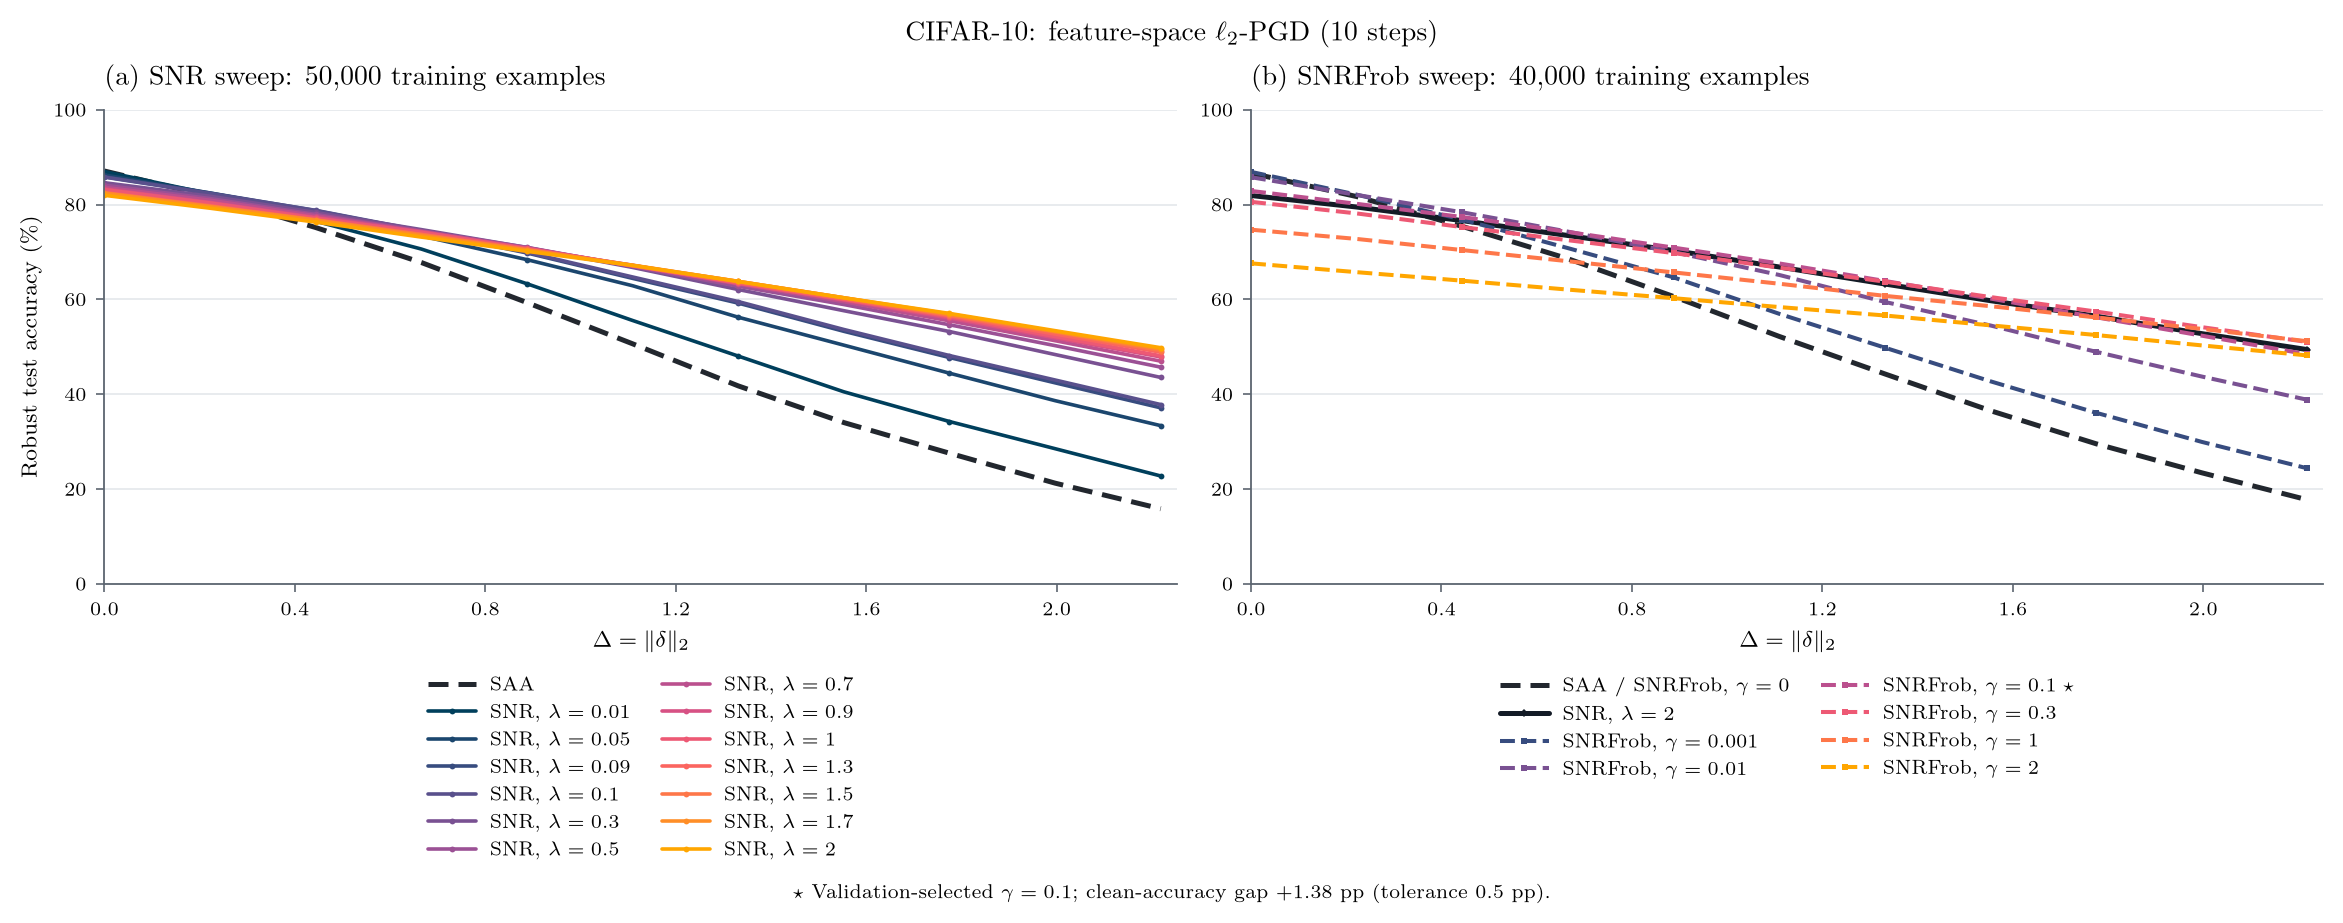

In [6]:
# Two panels keep the training cohorts distinct while retaining every lambda and gamma.
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), sharex=True, sharey=True,
                         constrained_layout=True)
for axis in axes:
    axis.set_axisbelow(True)
    axis.grid(axis='y', color='#dce1e6', linewidth=0.55, alpha=0.85)
    axis.spines[['top', 'right']].set_visible(False)
    axis.spines[['left', 'bottom']].set_color('#5c6570')
    axis.tick_params(direction='out', length=3, width=0.6, color='#5c6570')
    axis.set_xlabel(r'$\Delta = \|\delta\|_2$')
    axis.set_xlim(0, max(results['absolute_radius'].max(), grid_radii[-1]) * 1.015)
    axis.set_ylim(0, 100)
    axis.xaxis.set_major_locator(MultipleLocator(0.4))
    axis.yaxis.set_major_locator(MultipleLocator(20))
axes[0].set_ylabel(r'Robust test accuracy (\%)' if use_tex else 'Robust test accuracy (%)')
axes[1].tick_params(labelleft=True)

def draw_curve(axis, curve, label, color, linestyle='-', marker='o', width=1.3):
    curve = curve.sort_values('absolute_radius')
    axis.plot(curve['absolute_radius'], curve['mean'], color=color, label=label,
              linewidth=width, linestyle=linestyle, marker=marker, markersize=2.1,
              markevery=2, markeredgewidth=0, solid_capstyle='round')
    if (curve['seeds'] > 1).all():
        axis.fill_between(curve['absolute_radius'], curve['mean'] - curve['std'],
                          curve['mean'] + curve['std'], color=color, alpha=0.1, linewidth=0)

left, right = axes
left.set_title(r'(a) SNR sweep: 50,000 training examples', loc='left', pad=9)
right.set_title(rf'(b) SNRFrob sweep: {selection["fit_size"]:,} training examples', loc='left', pad=9)
draw_curve(left, summary.loc[summary['method'].eq('SAA')], 'SAA', '#22272e',
           linestyle=(0, (4, 2)), marker=None, width=1.8)
for coefficient, color in zip(lambdas, snr_colors):
    curve = summary.loc[summary['method'].eq('SNR') & summary['snr_lambda'].eq(coefficient)]
    draw_curve(left, curve, rf'SNR, $\lambda={coefficient:g}$', color)

# Gamma zero is identical to the SAA head in this paired run; show one shared trace.
zero_gamma = 0.0 in gammas
saa_label = r'SAA / SNRFrob, $\gamma=0$' if zero_gamma else 'SAA'
draw_curve(right, grid_summary.loc[grid_summary['method'].eq('SAA')], saa_label, '#22272e',
           linestyle=(0, (4, 2)), marker=None, width=1.8)
for coefficient in sorted(grid_summary.loc[grid_summary['method'].eq('SNR'), 'snr_lambda'].unique()):
    curve = grid_summary.loc[grid_summary['method'].eq('SNR') & grid_summary['snr_lambda'].eq(coefficient)]
    draw_curve(right, curve, rf'SNR, $\lambda={coefficient:g}$', '#131b26',
               linestyle='-', marker='D', width=1.8)

frob_palette = LinearSegmentedColormap.from_list('snrfrob_gamma', colors)
frob_colors = frob_palette(np.linspace(0, 1, len(gammas)))
for gamma, color in zip(gammas, frob_colors):
    if gamma == 0:
        continue
    curve = grid_summary.loc[grid_summary['method'].eq('SNRFrob') & grid_summary['snrfrob_gamma'].eq(gamma)]
    star = r'\;\star' if gamma == selected_gamma else ''
    draw_curve(right, curve, rf'SNRFrob, $\gamma={gamma:g}{star}$', color,
               linestyle='--', marker='s', width=1.45)

for axis in axes:
    axis.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False,
                handlelength=2.5, columnspacing=1.6, handletextpad=0.7,
                labelspacing=0.52, borderaxespad=0)
fig.suptitle(rf'CIFAR-10: feature-space $\ell_2$-PGD ({grid_steps} steps)', fontsize=10)
selection_note = (rf'$\star$ Validation-selected $\gamma={selected_gamma:g}$; clean-accuracy gap '
                  rf'${selection["signed_clean_accuracy_gap_pp"]:+.2f}$ pp '
                  rf'(tolerance ${selection["match_tolerance_pp"]:g}$ pp).')
fig.supxlabel(selection_note, fontsize=7)

comparison_dir = project_dir / 'results' / 'figures' / datetime.now().strftime('snr_snrfrob_sweeps_%Y%m%d_%H%M%S_%f')
comparison_dir.mkdir(parents=True, exist_ok=False)
for extension in ('pdf', 'png'):
    fig.savefig(comparison_dir / f'snr_snrfrob_test_sweeps.{extension}', dpi=600, bbox_inches='tight')
combined_rows = pd.concat([
    results.assign(plot_panel='historical SNR sweep', evaluation_split='test', training_examples=50000),
    grid_plot_rows.assign(plot_panel='SNRFrob grid run', evaluation_split='test', training_examples=selection['fit_size']),
], ignore_index=True)
combined_rows.to_csv(comparison_dir / 'plotted_test_results.csv', index=False)
print(f'Combined test figure saved to: {comparison_dir.relative_to(project_dir)}')
plt.show()

## Singular-direction diagnostics: SAA and SNR

These figures use the saved **50,000-training-image** heads: SAA, SNR $\lambda=0.3$,
and SNR $\lambda=2$, all with seed 2022 and 10 epochs. No head is retrained.
Each figure has one row per head and three columns:

1. The singular spectrum of the **class-row-centered** head, divided by its largest singular value.
   The annotation gives its absolute $\sigma_1$ and stable rank.
2. Direction energy captured by the first $k$ right singular vectors.
   Clean directions use **training class centroids**. The third curve first projects each
   clean direction into the row space, then normalizes it. All heads use the same
   intersection of clean-correct test examples.
3. **Exact feature-space robust accuracy** on all 10,000 test examples. The controls use
   training within-class PCs and 50 random subspaces of the head's row space.
   The band is the 10th--90th percentile across random subspaces, not a confidence interval.

Here $q\in\{0.04,0.08\}$ and $\Delta=q\,\mathrm{mean}_i\|h_i\|_2$.
All heads use the current cache and the same absolute radius. Its mean test norm differs
slightly from the saved runs. The table below reports both values and both clean accuracies.
These are fresh common-cache diagnostics. Exact robust accuracy is a different metric from
the earlier 10-step PGD accuracy.

The spectrum uses $W-\mathrm{mean}_{\rm classes}(W)$. Its $\sigma_1$ can differ from the
uncentered operator norm used in the training penalty. Near-tied singular values
(relative gap at most $10^{-3}$ of $\sigma_1$) stay together in the subspace curves.
The reference $k/r$ describes an isotropic direction in the rank-$r$ row space.
Capture of all adversarial energy at $k=r=9$ is a geometry check.


In [7]:
import hashlib
import subprocess
import sys
import torch

diagnostic_root = Path.cwd()
if not (diagnostic_root / 'snr_directions.py').is_file():
    raise FileNotFoundError('Run this notebook from the repository root.')
diagnostic_script = diagnostic_root / 'snr_directions.py'
diagnostic_cache_path = diagnostic_root / 'cifar10_resnet18_imagenet1k_v1_features.pth'
diagnostic_heads = {
    'SAA': diagnostic_root / 'results/cifar10_resnet18/20261109_142917_95256f93/SAA_9eaa113a0004/seed_2022/final.pth',
    'SNR_0.3': diagnostic_root / 'results/cifar10_resnet18/20261109_142917_95256f93/SNR_4ed82ee95888/seed_2022/final.pth',
    'SNR_2': diagnostic_root / 'results/cifar10_resnet18/20261109_143622_171c45d6/SNR_013815e3fd78/seed_2022/final.pth',
}
diagnostic_levels = [(0.04, '004'), (0.08, '008')]
diagnostic_draws = 50
diagnostic_seed = 2022

diagnostic_code_dir = diagnostic_root / 'CIFAR10_feature_regression'
if str(diagnostic_code_dir) not in sys.path:
    sys.path.insert(0, str(diagnostic_code_dir))
import Multiclass_classification as diagnostic_experiment

diagnostic_cache = torch.load(diagnostic_cache_path, map_location='cpu', weights_only=True)
diagnostic_experiment.validate_feature_cache(diagnostic_cache)
diagnostic_mean_norm = torch.linalg.vector_norm(
    diagnostic_cache['test_features'], dim=1).mean().item()
diagnostic_states = {}
diagnostic_source_rows = []
diagnostic_common_hp = None
for name, head_path in diagnostic_heads.items():
    checkpoint = torch.load(head_path, map_location='cpu', weights_only=True)
    run_metadata = json.loads((head_path.parents[2] / 'experiment.json').read_text())
    if run_metadata['arguments'].get('snrfrob_gamma_grid'):
        raise ValueError(f'{name}: the requested comparison must use the full-training run.')
    if checkpoint['feature_metadata'] != diagnostic_cache['metadata']:
        raise ValueError(f'{name}: incompatible feature metadata.')
    expected_method = 'SAA' if name == 'SAA' else 'SNR'
    hp = checkpoint['hyperparameters']
    if (checkpoint['method'] != expected_method or checkpoint['seed'] != diagnostic_seed
            or hp['epochs'] != 10):
        raise ValueError(f'{name}: unexpected method, seed, or epochs.')
    if name != 'SAA' and hp['snr_lambda'] != float(name.split('_')[1]):
        raise ValueError(f'{name}: incorrect lambda.')
    paired_hp = {key: value for key, value in hp.items() if key != 'snr_lambda'}
    if diagnostic_common_hp is None:
        diagnostic_common_hp = paired_hp
    elif paired_hp != diagnostic_common_hp:
        raise ValueError('The heads do not have the same clean training settings.')
    diagnostic_states[name] = checkpoint
    diagnostic_source_rows.append({
        'head': name, 'saved_mean_test_norm': checkpoint['mean_test_norm'],
        'current_mean_test_norm': diagnostic_mean_norm,
        'saved_clean_accuracy': checkpoint['results'][0.0],
    })

def diagnostic_sha256(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

diagnostic_files = [diagnostic_cache_path, diagnostic_script, *diagnostic_heads.values()]
diagnostic_hashes = {str(p.relative_to(diagnostic_root)): diagnostic_sha256(p)
                     for p in diagnostic_files}
diagnostic_key = hashlib.sha256(json.dumps({
    'sources': diagnostic_hashes, 'draws': diagnostic_draws, 'seed': diagnostic_seed,
}, sort_keys=True).encode()).hexdigest()[:16]
diagnostic_data_dir = diagnostic_root / 'results/derived/snr_directions' / diagnostic_key

diagnostic_frames = []
for level, tag in diagnostic_levels:
    out_dir = diagnostic_data_dir / f'level_{tag}'
    command = [sys.executable, str(diagnostic_script), '--features', str(diagnostic_cache_path)]
    for name, head_path in diagnostic_heads.items():
        command.extend(['--head', f'{name}={head_path}'])
    command.extend(['--level', str(level), '--draws', str(diagnostic_draws),
                    '--seed', str(diagnostic_seed), '--out', str(out_dir)])
    csv_path = out_dir / 'directions.csv'
    provenance_path = out_dir / 'provenance.json'
    if not csv_path.is_file() or not provenance_path.is_file():
        print(f'Run exact diagnostics at q={level:g}.', flush=True)
        completed = subprocess.run(command, cwd=diagnostic_root, check=True,
                                   capture_output=True, text=True)
        print(completed.stdout)
        if completed.stderr:
            print(completed.stderr)
    else:
        print(f'Load exact diagnostics: {csv_path.relative_to(diagnostic_root)}')
    provenance = json.loads(provenance_path.read_text())
    if provenance['feature_cache']['sha256'] != diagnostic_hashes[str(diagnostic_cache_path.relative_to(diagnostic_root))]:
        raise ValueError('The diagnostic cache hash does not match.')
    if provenance['script_sha256'] != diagnostic_hashes['snr_directions.py']:
        raise ValueError('The diagnostic script hash does not match.')
    for name, head_path in diagnostic_heads.items():
        if provenance['heads'][name]['sha256'] != diagnostic_hashes[str(head_path.relative_to(diagnostic_root))]:
            raise ValueError(f'{name}: the checkpoint hash does not match.')
    if (provenance['random_draws'] != diagnostic_draws or provenance['random_seed'] != diagnostic_seed
            or provenance['retrained'] or provenance['training_examples'] != 50000
            or provenance['test_examples'] != 10000 or provenance['level'] != level):
        raise ValueError('The diagnostic settings do not match.')
    frame = pd.read_csv(csv_path)
    if set(frame['head']) != set(diagnostic_heads):
        raise ValueError('A diagnostic head is missing.')
    np.testing.assert_allclose(frame['mean_test_norm'], diagnostic_mean_norm, rtol=0, atol=1e-12)
    np.testing.assert_allclose(frame['radius'], level * diagnostic_mean_norm, rtol=0, atol=1e-12)
    np.testing.assert_allclose(frame['level'], level, rtol=0, atol=1e-12)
    for name, group in frame.groupby('head'):
        group = group.sort_values('k')
        np.testing.assert_array_equal(group['k'], np.arange(1, 10))
        if not group['rank'].eq(9).all() or not group['evaluation_n'].eq(10000).all():
            raise ValueError(f'{name}: unexpected rank or test count.')
        accuracy_columns = ['head_subspace_accuracy', 'clean_pc_accuracy', 'random_rowspace_median',
                            'random_rowspace_p10', 'random_rowspace_p90']
        for column in accuracy_columns:
            values = group[column].to_numpy()
            if (not np.isfinite(values).all() or np.any(np.diff(values) > 1e-9)
                    or np.any(values < group['unrestricted_accuracy'].to_numpy() - 1e-9)
                    or np.any(values > group['clean_accuracy'].to_numpy() + 1e-9)):
                raise ValueError(f'{name}: invalid accuracy curve {column}.')
        if np.any(group['random_rowspace_p10'] > group['random_rowspace_median']) or np.any(
                group['random_rowspace_median'] > group['random_rowspace_p90']):
            raise ValueError(f'{name}: invalid random-subspace band.')
        np.testing.assert_allclose(group.iloc[-1][['head_subspace_accuracy', 'random_rowspace_p10',
                                                   'random_rowspace_median', 'random_rowspace_p90']].astype(float),
                                   group.iloc[-1]['unrestricted_accuracy'], rtol=0, atol=1e-9)
        for column in ['mean_clean_energy', 'mean_clean_conditional', 'mean_adversarial_energy']:
            values = group[column].to_numpy()
            if (not np.isfinite(values).all() or np.any(values < -1e-10)
                    or np.any(values > 1 + 1e-10) or np.any(np.diff(values) < -1e-10)):
                raise ValueError(f'{name}: invalid direction energy {column}.')
        np.testing.assert_allclose(group.iloc[-1][['mean_adversarial_energy', 'mean_clean_conditional']].astype(float),
                                   1.0, rtol=0, atol=1e-10)
    diagnostic_frames.append(frame)

diagnostic_results = pd.concat(diagnostic_frames, ignore_index=True)
fixed_columns = ['sigma', 'relative_sigma', 'stable_rank', 'relative_gap_after', 'identifiable_cut',
                 'mean_clean_energy', 'mean_clean_conditional', 'mean_adversarial_energy',
                 'clean_accuracy', 'common_correct_n', 'clean_direction_n', 'conditional_n']
pd.testing.assert_frame_equal(
    diagnostic_frames[0].set_index(['head', 'k'])[fixed_columns].sort_index(),
    diagnostic_frames[1].set_index(['head', 'k'])[fixed_columns].sort_index())
if diagnostic_results['common_correct_n'].nunique() != 1:
    raise ValueError('Direction comparisons use different test examples.')
for relative_path, expected_hash in diagnostic_hashes.items():
    if diagnostic_sha256(diagnostic_root / relative_path) != expected_hash:
        raise ValueError(f'An input file changed: {relative_path}')

diagnostic_source_table = pd.DataFrame(diagnostic_source_rows).set_index('head')
diagnostic_source_table['current_clean_accuracy'] = diagnostic_frames[0].groupby('head')['clean_accuracy'].first()
display(diagnostic_source_table.round(6))
print(f'Geometry checks passed. Common clean-correct examples: {diagnostic_results.common_correct_n.iloc[0]:,}.')
print(f'Mean test norm: {diagnostic_mean_norm:.12g}. Radii: {[q * diagnostic_mean_norm for q, _ in diagnostic_levels]}.')


Load exact diagnostics: results\derived\snr_directions\1dca942a91976108\level_004\directions.csv
Load exact diagnostics: results\derived\snr_directions\1dca942a91976108\level_008\directions.csv


,saved_mean_test_norm,current_mean_test_norm,saved_clean_accuracy,current_clean_accuracy
head,,,,
SAA,27.733925,27.736544,87.08,87.09
SNR_0.3,27.733925,27.736544,84.61,84.60
SNR_2,27.733925,27.736544,81.95,81.95


Geometry checks passed. Common clean-correct examples: 7,861.
Mean test norm: 27.7365436554. Radii: [1.1094617462158203, 2.2189234924316406].


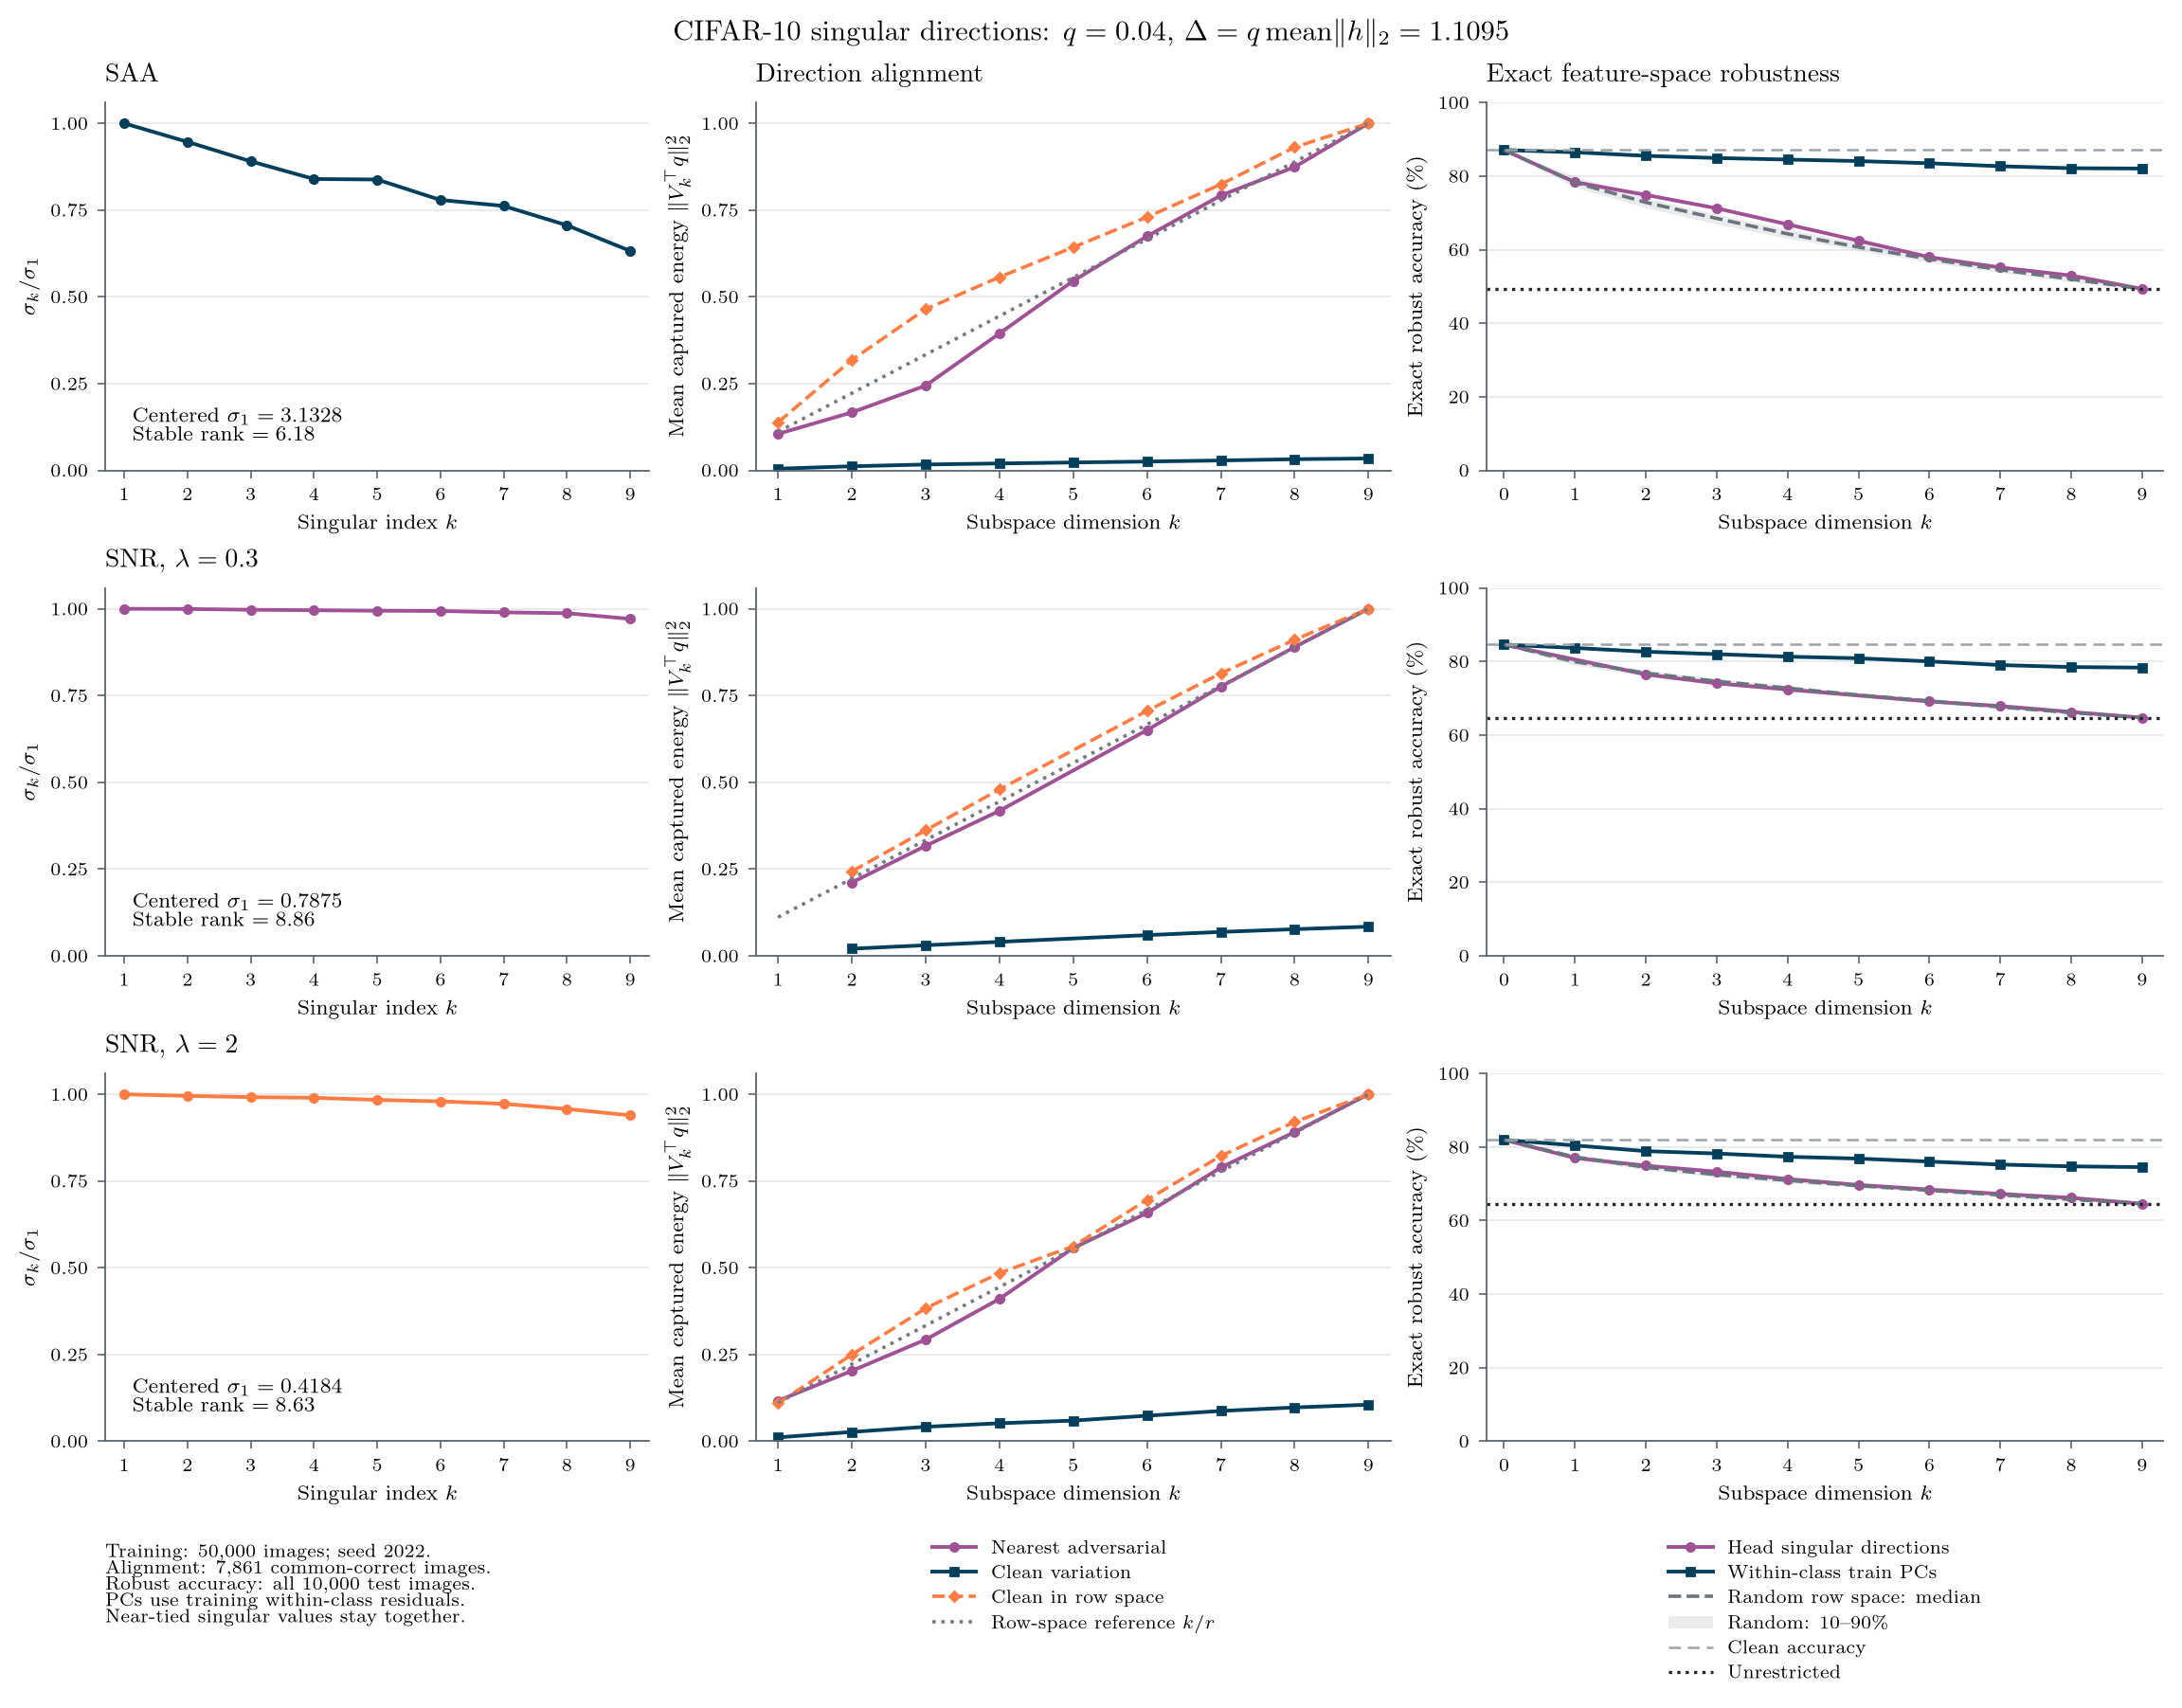

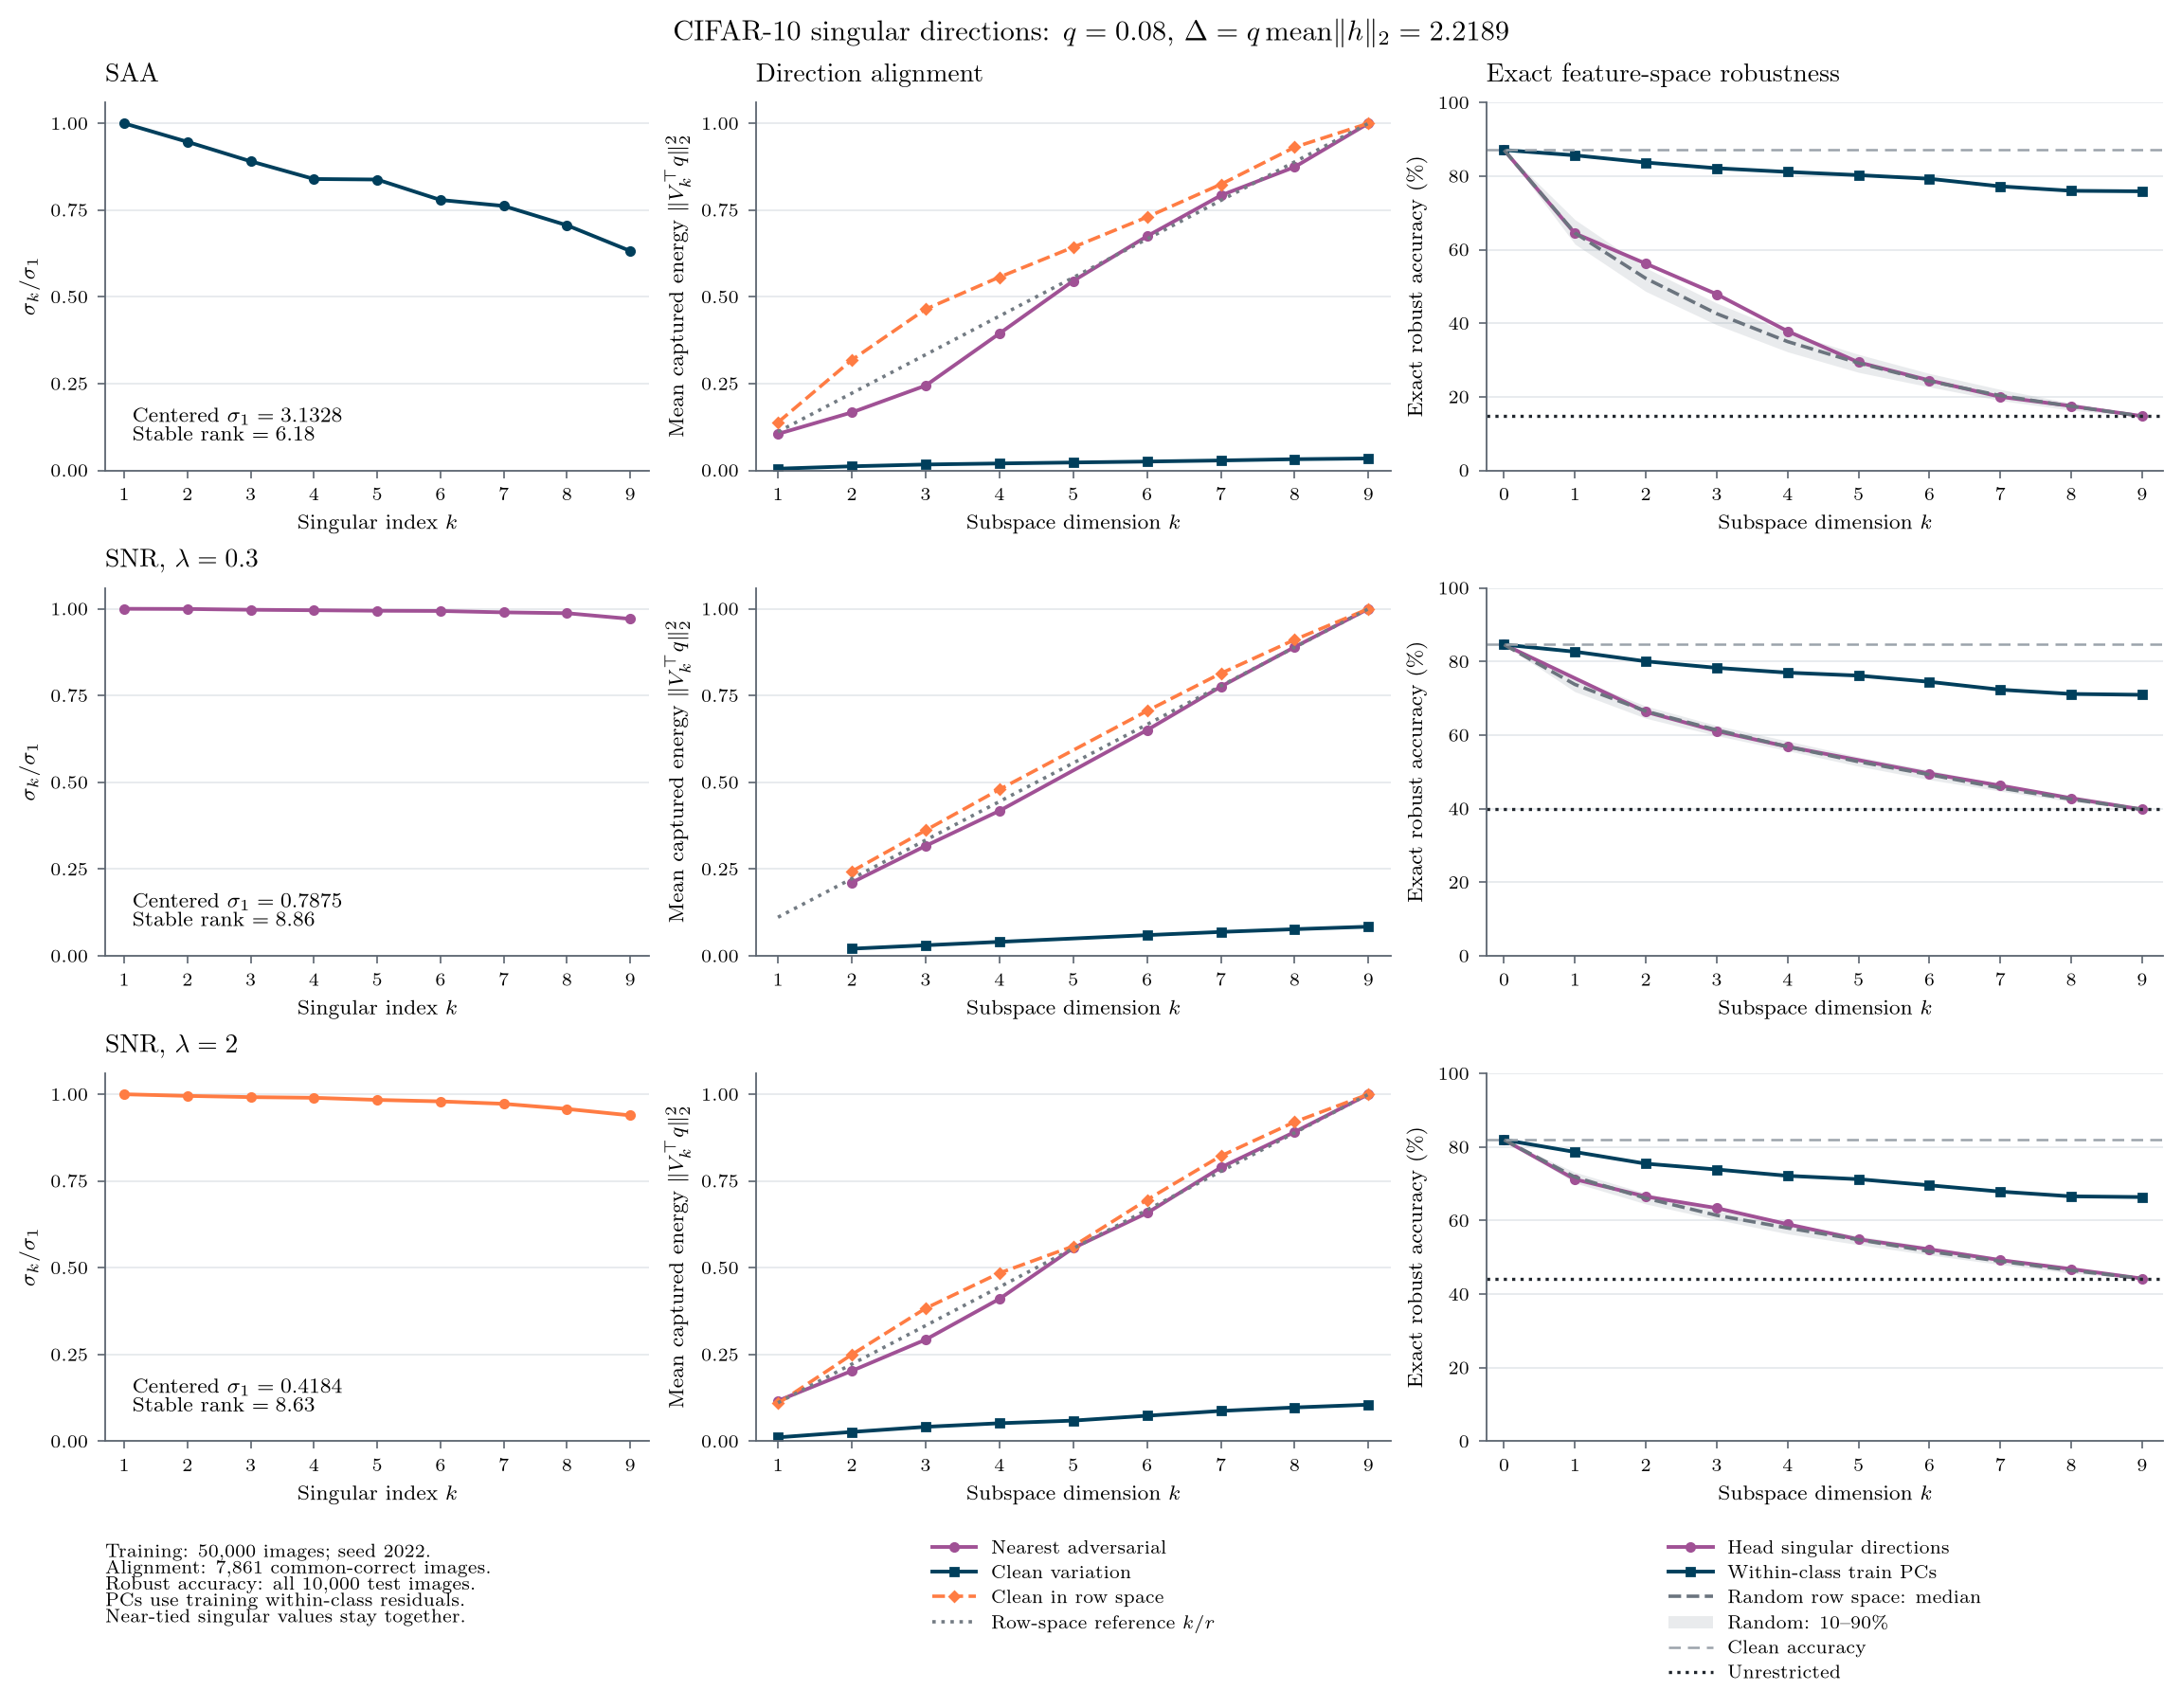

,head,level,radius,clean_accuracy,unrestricted_accuracy,head_subspace_accuracy,random_rowspace_median,mean_adversarial_energy,mean_clean_energy,top2_share_of_full_accuracy_drop,random2_share_of_full_accuracy_drop
1,SAA,0.04,1.1095,87.09,49.33,74.89,72.850,0.1669,0.0117,0.3231,0.3771
10,SNR_0.3,0.04,1.1095,84.60,64.75,76.50,76.850,0.2111,0.0205,0.4081,0.3904
19,SNR_2,0.04,1.1095,81.95,64.59,74.93,74.490,0.2029,0.0269,0.4044,0.4297
28,SAA,0.08,2.2189,87.09,14.74,56.20,52.190,0.1669,0.0117,0.4270,0.4824
37,SNR_0.3,0.08,2.2189,84.60,39.80,66.32,66.510,0.2111,0.0205,0.4080,0.4038
46,SNR_2,0.08,2.2189,81.95,44.23,66.54,66.075,0.2029,0.0269,0.4085,0.4209


Figures and plotted data: results\figures\snr_directions_20261109_180725_965125


In [8]:
diagnostic_labels = {'SAA': 'SAA', 'SNR_0.3': r'SNR, $\lambda=0.3$', 'SNR_2': r'SNR, $\lambda=2$'}
diagnostic_output_dir = diagnostic_root / 'results/figures' / datetime.now().strftime('snr_directions_%Y%m%d_%H%M%S_%f')
diagnostic_output_dir.mkdir(parents=True, exist_ok=False)
diagnostic_results.to_csv(diagnostic_output_dir / 'plotted_directions.csv', index=False)
(diagnostic_output_dir / 'sources.json').write_text(json.dumps({
    'source_hashes': diagnostic_hashes, 'data_directory': str(diagnostic_data_dir.relative_to(diagnostic_root)),
    'random_draws': diagnostic_draws, 'random_seed': diagnostic_seed,
    'mean_test_norm': diagnostic_mean_norm, 'levels': [q for q, _ in diagnostic_levels],
}, indent=2))

for level, tag in diagnostic_levels:
    fig, axes = plt.subplots(3, 3, figsize=(11.4, 8.9), constrained_layout=True,
                             gridspec_kw={'width_ratios': [0.9, 1.05, 1.12]})
    for row, (name, label) in enumerate(diagnostic_labels.items()):
        curve = diagnostic_results.loc[
            diagnostic_results['head'].eq(name) & diagnostic_results['level'].eq(level)
        ].sort_values('k')
        ks = curve['k'].to_numpy()
        cut = curve['identifiable_cut'].to_numpy(dtype=bool)
        sax, dax, rax = axes[row]
        for axis in (sax, dax, rax):
            axis.set_axisbelow(True)
            axis.spines[['top', 'right']].set_visible(False)
            axis.spines[['left', 'bottom']].set_color('#5c6570')
            axis.tick_params(direction='out', length=3, width=0.6, color='#5c6570')
            axis.grid(axis='y', color='#dce1e6', linewidth=0.55, alpha=0.85)
            axis.set_xticks(ks)
            axis.set_xlim(0.7, 9.3)
            axis.set_xlabel(r'Subspace dimension $k$')
        sax.set_title(label, loc='left', pad=8)
        sax.plot(ks, curve['relative_sigma'], color=[colors[0], colors[3], colors[6]][row],
                 marker='o', markersize=3, linewidth=1.4)
        sax.set_xlabel(r'Singular index $k$')
        sax.set_ylabel(r'$\sigma_k/\sigma_1$')
        sax.set_ylim(0, 1.06)
        sax.yaxis.set_major_locator(MultipleLocator(0.25))
        sax.text(0.05, 0.07, rf'Centered $\sigma_1={curve.sigma.iloc[0]:.4f}$' + '\n'
                 + rf'Stable rank $={curve.stable_rank.iloc[0]:.2f}$',
                 transform=sax.transAxes, fontsize=8, va='bottom', linespacing=1.6)
        dax.plot(ks[cut], curve.loc[cut, 'mean_adversarial_energy'], color=colors[3],
                 marker='o', markersize=3, linewidth=1.4, label='Nearest adversarial')
        dax.plot(ks[cut], curve.loc[cut, 'mean_clean_energy'], color=colors[0],
                 marker='s', markersize=2.7, linewidth=1.4, label='Clean variation')
        dax.plot(ks[cut], curve.loc[cut, 'mean_clean_conditional'], color=colors[6],
                 marker='D', markersize=2.5, linewidth=1.3, linestyle='--', label='Clean in row space')
        dax.plot(ks, ks / curve['rank'].iloc[0], color='#737b83', linestyle=':', linewidth=1.3,
                 label=r'Row-space reference $k/r$')
        dax.set_ylabel(r'Mean captured energy $\|V_k^\top q\|_2^2$')
        dax.set_ylim(0, 1.06)
        dax.yaxis.set_major_locator(MultipleLocator(0.25))

        # Dimension zero makes the clean baseline explicit for every attack family.
        rax.plot(np.r_[0, ks[cut]], np.r_[curve.clean_accuracy.iloc[0], curve.loc[cut, 'head_subspace_accuracy']],
                 color=colors[3], marker='o', markersize=3, linewidth=1.4, label='Head singular directions')
        rax.plot(np.r_[0, ks], np.r_[curve.clean_accuracy.iloc[0], curve['clean_pc_accuracy']],
                 color=colors[0], marker='s', markersize=2.7, linewidth=1.4, label='Within-class train PCs')
        rax.plot(np.r_[0, ks], np.r_[curve.clean_accuracy.iloc[0], curve['random_rowspace_median']],
                 color='#6b747e', linestyle='--', linewidth=1.3, label='Random row space: median')
        rax.fill_between(np.r_[0, ks], np.r_[curve.clean_accuracy.iloc[0], curve['random_rowspace_p10']],
                         np.r_[curve.clean_accuracy.iloc[0], curve['random_rowspace_p90']],
                         color='#89939d', alpha=0.18, linewidth=0,
                         label=r'Random: 10--90\%' if use_tex else 'Random: 10-90%')
        rax.axhline(curve['clean_accuracy'].iloc[0], color='#9ba3ab', linewidth=0.9,
                    linestyle=(0, (5, 3)), label='Clean accuracy')
        rax.axhline(curve['unrestricted_accuracy'].iloc[0], color='#20262d', linewidth=1.2,
                    linestyle=':', label='Unrestricted')
        rax.set_xlim(-0.25, 9.3)
        rax.set_xticks(np.arange(10))
        rax.set_ylim(0, 100)
        rax.yaxis.set_major_locator(MultipleLocator(20))
        rax.set_ylabel(r'Exact robust accuracy (\%)' if use_tex else 'Exact robust accuracy (%)')
        if row == 0:
            dax.set_title('Direction alignment', loc='left', pad=8)
            rax.set_title('Exact feature-space robustness', loc='left', pad=8)
    for column in (1, 2):
        axes[-1, column].legend(loc='upper center', bbox_to_anchor=(0.5, -0.25),
                                frameon=False, ncol=1, handlelength=2.4,
                                labelspacing=0.45, borderaxespad=0)
    axes[-1, 0].text(0, -0.28, 'Training: 50,000 images; seed 2022.\n'
                    + f'Alignment: {int(curve.common_correct_n.iloc[0]):,} common-correct images.\n'
                    + 'Robust accuracy: all 10,000 test images.\n'
                    + 'PCs use training within-class residuals.\n'
                    + 'Near-tied singular values stay together.',
                    transform=axes[-1, 0].transAxes, fontsize=7, va='top', linespacing=1.55)
    fig.suptitle(rf'CIFAR-10 singular directions: $q={level:g}$, '
                 rf'$\Delta=q\,\mathrm{{mean}}\|h\|_2={level * diagnostic_mean_norm:.4f}$',
                 fontsize=11)
    for extension in ('pdf', 'png'):
        fig.savefig(diagnostic_output_dir / f'directions_{tag}.{extension}', dpi=600, bbox_inches='tight')
    plt.show()

diagnostic_summary = diagnostic_results.loc[diagnostic_results['k'].eq(2), [
    'head', 'level', 'radius', 'clean_accuracy', 'unrestricted_accuracy',
    'head_subspace_accuracy', 'random_rowspace_median', 'mean_adversarial_energy', 'mean_clean_energy',
]].copy()
diagnostic_summary['top2_share_of_full_accuracy_drop'] = (
    (diagnostic_summary['clean_accuracy'] - diagnostic_summary['head_subspace_accuracy'])
    / (diagnostic_summary['clean_accuracy'] - diagnostic_summary['unrestricted_accuracy']))
diagnostic_summary['random2_share_of_full_accuracy_drop'] = (
    (diagnostic_summary['clean_accuracy'] - diagnostic_summary['random_rowspace_median'])
    / (diagnostic_summary['clean_accuracy'] - diagnostic_summary['unrestricted_accuracy']))
diagnostic_summary.to_csv(diagnostic_output_dir / 'top_two_summary.csv', index=False)
display(diagnostic_summary.round(4))
print(f'Figures and plotted data: {diagnostic_output_dir.relative_to(diagnostic_root)}')


### Reading these results

These heads do **not** show that the first two SAA singular directions account for most
adversarial errors. At $q=0.08$, the first two SAA directions account for about 43% of its
full-space clean-to-robust accuracy drop. The median random two-dimensional subspace accounts
for about 48%. The nearest adversarial directions put about 17% of their energy in those two
SAA directions, below the row-space reference $2/9\approx22\%$.

SNR makes the spectrum much flatter. The restricted-accuracy curves do not show a clear
advantage of its leading two directions over random two-dimensional subspaces.
Most ordinary within-class direction energy lies outside the decision row space for all
three heads. Use the conditional clean curve to compare directions *inside* that space.

These results describe the three saved heads from one seed. The random-subspace band shows
variation among controls for each fixed head; it does not measure variation across training seeds.
